In [1]:
import os
import sys
import numpy as np
import pandas as pd
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import savgol_filter
from sklearn.model_selection import train_test_split

import scanpy as sc
import anndata

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    HfArgumentParser,
    TrainingArguments,
    Trainer,
    default_data_collator,
)
from peft import (
    LoraConfig,
    PeftConfig,
    PeftModel,
    get_peft_model,
)

from dataclasses import dataclass, field
from typing import Optional
from enum import Enum
import evaluate

sys.path.append("..")
from lib_vqvae.vqvae import VQVAE
from lib_vqvae.dataset import *

#### Load the pre-trained cell tokenizer

In [2]:
import warnings
warnings.filterwarnings("ignore")
import argparse

parser = argparse.ArgumentParser()
parser.add_argument("--train_batch_size", type=int, default=64)
parser.add_argument("--eval_batch_size", type=int, default=2000)
parser.add_argument("--encoder_hidden_dim", type=list, default=[1600,1024,800])
parser.add_argument("--decoder_hidden_dim", type=list, default=[800,1024,1600])
parser.add_argument("--codebook_dim", type=int, default=8)
parser.add_argument("--n", type=int, default=32)
parser.add_argument("--n_codebooks", type=int, default=256)
parser.add_argument("--gamma", type=float, default=5)
parser.add_argument("--beta", type=float, default=10)
parser.add_argument('--weight_decay', type=float, default=5e-4)
parser.add_argument("--lr", type=float, default=1e-4) # 1e-3
parser.add_argument('--max_iter', type=int, default=20)
parser.add_argument('--seed', type=int, default=2024)
parser.add_argument('--gpu', type=int, default=0)
parser.add_argument("--dropout_rate", type=float, default=0.2)
parser.add_argument('--mode', type=str, default="vqvae")
parser.add_argument('--hvg', type=int, default=5000)

args = parser.parse_args([])

# -- device
if torch.cuda.is_available():
    args.device='cuda'
    torch.cuda.set_device(args.gpu)
else:
    args.device='cpu' 
print(args.device)
    
data_dim = 5000
vae = VQVAE(data_dim, args.n, args.codebook_dim, args.n_codebooks, args.encoder_hidden_dim, args.decoder_hidden_dim, args.beta, args.gamma, args.dropout_rate).to(args.device)

vae.load_state_dict(torch.load('../model/cell_tokenzier/model.pth')['model'])
vae.eval() 

cuda


VQVAE(
  (encoder): Encoder(
    (network): Sequential(
      (0): Linear(in_features=5000, out_features=1600, bias=True)
      (1): LayerNorm((1600,), eps=1e-05, elementwise_affine=True)
      (2): PReLU(num_parameters=1)
      (3): Dropout(p=0.2, inplace=False)
      (4): Linear(in_features=1600, out_features=1024, bias=True)
      (5): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
      (6): PReLU(num_parameters=1)
      (7): Dropout(p=0.2, inplace=False)
      (8): Linear(in_features=1024, out_features=800, bias=True)
      (9): LayerNorm((800,), eps=1e-05, elementwise_affine=True)
      (10): PReLU(num_parameters=1)
      (11): Dropout(p=0.2, inplace=False)
      (12): Linear(in_features=800, out_features=256, bias=True)
    )
  )
  (vector_quantization): VectorQuantizer(
    (embedding): Embedding(256, 8)
  )
  (decoder): Decoder(
    (network): Sequential(
      (0): Linear(in_features=256, out_features=800, bias=True)
      (1): LayerNorm((800,), eps=1e-05, elementwise

#### Prepare Model and Tokenizer
Now, we will be adding 258 new tokens as well as replace the existing pad, bos and eos tokens of the model.

In [3]:
# Define new tokens
new_tokens = [f'<code_{i}>' for i in range(256)] + ['<cell_token_start>', '<cell_token_end>']

In [4]:
model_name = "your path to the LLM backbone"  # load the base LLM backbone
tokenizer_path = "your path to LLM's tokenizer"  # load the LLM toknizer

tokenizer = AutoTokenizer.from_pretrained(
    tokenizer_path,
    pad_token="<|pad|>",
    eos_token="<|endsentence|>",
    additional_special_tokens=new_tokens,
)

In [5]:
len(tokenizer)

151925

#### Load the processed dataset.

In [2]:
from datasets import load_dataset, load_from_disk
from tqdm import tqdm

processed_datasets = load_from_disk("../data/blood/tokenized_dataset_generation/")

Loading dataset from disk:   0%|          | 0/30 [00:00<?, ?it/s]

random select 1000 samples for test

In [14]:
eval_subset = processed_datasets
# eval_subset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
eval_subset = eval_subset.shuffle(seed=42).select(range(100))
eval_subset

Dataset({
    features: ['index_name', 'i', 'code', 'story', 'match', 'input_text', 'output_text', 'input_ids', 'attention_mask', 'labels'],
    num_rows: 100
})

#### Load the pre-trained CellTok model

In [ ]:
from peft import PeftModel

inference_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    low_cpu_mem_usage=True,
)
inference_model.resize_token_embeddings(len(tokenizer))

inference_model = PeftModel.from_pretrained(inference_model, "your path to CellTok-base")

inference_model.to("cuda")
inference_model.eval()

#### Get the codes 

##### ground truth

In [12]:
import re

output_texts = eval_subset["output_text"]
stories = eval_subset["story"]

celltype_list = []

pattern = r"is an? (.*?) from"

for story in stories:
    match = re.search(pattern, story)
    if match:
        cell_type = match.group(1).strip()
        celltype_list.append(cell_type)
    else:
        celltype_list.append("unknown")

extracted_codes = []
code_pattern = r"<code_(\d+)>"

for text in output_texts:
    cell_content = re.search(r"<cell_token_start>(.*?)<cell_token_end>", text)
    if cell_content:
        codes = re.findall(code_pattern, cell_content.group(1))
        extracted_codes.append([int(code) for code in codes])
        
eval_subset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
extracted_codes_gt = extracted_codes
extracted_codes_gt

[[166,
  2,
  15,
  146,
  15,
  175,
  29,
  236,
  24,
  174,
  216,
  200,
  159,
  245,
  22,
  107,
  211,
  186,
  240,
  192,
  58,
  202,
  186,
  66,
  75,
  175,
  88,
  128,
  213,
  24,
  75,
  225],
 [163,
  66,
  75,
  241,
  52,
  57,
  252,
  114,
  20,
  13,
  206,
  200,
  96,
  188,
  188,
  248,
  219,
  15,
  2,
  118,
  254,
  14,
  168,
  23,
  75,
  40,
  88,
  102,
  100,
  170,
  231,
  199],
 [224,
  15,
  106,
  234,
  132,
  38,
  188,
  111,
  246,
  14,
  132,
  197,
  188,
  1,
  59,
  96,
  143,
  0,
  75,
  159,
  159,
  223,
  14,
  246,
  241,
  163,
  35,
  75,
  188,
  57,
  2,
  50],
 [159,
  1,
  210,
  71,
  252,
  35,
  66,
  219,
  18,
  233,
  110,
  249,
  20,
  10,
  202,
  188,
  224,
  249,
  31,
  245,
  170,
  159,
  223,
  1,
  174,
  4,
  117,
  187,
  196,
  94,
  2,
  110],
 [151,
  170,
  96,
  15,
  107,
  128,
  187,
  211,
  174,
  160,
  225,
  161,
  45,
  118,
  174,
  13,
  192,
  16,
  136,
  219,
  243,
  18,
  1,
  65,
  

##### Predictions

In [15]:
import re
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm

def process_sample(idx, sample):
    try:
        sample = {k: v.unsqueeze(0) for k, v in sample.items()} 
        sample = {k: v.to("cuda") for k, v in sample.items()}  

        outputs = inference_model(**sample)

        valid_label_positions = (sample['labels'] == -100) & (sample['attention_mask'] == 1)
        filtered_input_ids = sample['input_ids'][valid_label_positions]

        output_tokens = inference_model.generate(
            filtered_input_ids.unsqueeze(0),
            max_new_tokens=256,
            do_sample=True,
            temperature=0.2,
            top_p=0.95,
            top_k=50,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.pad_token_id,
        )

        generated_text = tokenizer.decode(output_tokens[0], skip_special_tokens=False)

        match = re.search(r"<cell_token_start>(.*?)<cell_token_end>", generated_text)
        if match:
            cell_content = match.group(1)  
            numeric_values = re.findall(r"\d+", cell_content)
            numeric_values = list(map(int, numeric_values))  
            return idx, numeric_values
        else:
            return idx, []
    except Exception as e:
        return idx, f"Error: {str(e)}"

results = [None] * len(eval_subset)  
with ThreadPoolExecutor(max_workers=8) as executor:  
    futures = {executor.submit(process_sample, idx, sample): idx for idx, sample in enumerate(eval_subset)}

    for future in tqdm(as_completed(futures), total=len(futures), desc="Processing samples"):
        idx, result = future.result()  
        results[idx] = result 

extracted_codes_pred = results
extracted_codes_pred

Processing samples: 100%|██████████| 100/100 [05:11<00:00,  3.12s/it]


[[241,
  66,
  110,
  97,
  62,
  58,
  29,
  1,
  170,
  196,
  227,
  236,
  219,
  88,
  96,
  68,
  24,
  15,
  169,
  192,
  58,
  33,
  54,
  212,
  75,
  186,
  7,
  128,
  208,
  96,
  2,
  199],
 [169,
  2,
  75,
  163,
  164,
  58,
  139,
  161,
  254,
  217,
  128,
  89,
  219,
  124,
  111,
  63,
  24,
  186,
  241,
  111,
  118,
  57,
  168,
  212,
  66,
  75,
  118,
  152,
  71,
  96,
  231,
  224],
 [169,
  66,
  75,
  240,
  164,
  58,
  150,
  1,
  96,
  196,
  144,
  45,
  65,
  124,
  161,
  197,
  24,
  224,
  241,
  118,
  3,
  33,
  186,
  212,
  110,
  136,
  88,
  128,
  251,
  89,
  2,
  199],
 [159,
  245,
  203,
  223,
  4,
  47,
  212,
  219,
  217,
  236,
  110,
  161,
  148,
  56,
  232,
  65,
  36,
  27,
  31,
  70,
  243,
  59,
  223,
  45,
  170,
  252,
  165,
  75,
  95,
  168,
  2,
  75],
 [3,
  202,
  89,
  15,
  153,
  128,
  22,
  211,
  24,
  97,
  0,
  219,
  70,
  96,
  196,
  18,
  245,
  120,
  144,
  118,
  68,
  132,
  236,
  159,
  58,
  73

#### Decode

In [17]:
import torch

def decode_code_lists(code_list, vae):
    vector_quantizer = vae.vector_quantization
    embeddings = torch.stack([
        vector_quantizer.embedding.weight[torch.tensor(code_int, dtype=torch.long)]
        for code_int in code_list
    ])

    concatenated_embeddings = embeddings.view(embeddings.shape[0], -1)

    decoder = vae.decoder
    output = decoder(concatenated_embeddings)

    return output

Concat the decoded expression value to adata

In [18]:
valid_indices = [
    i for i, code in enumerate(extracted_codes_pred) 
    if len(code) == 32 
]

extracted_codes_pred = [extracted_codes_pred[i] for i in valid_indices]
extracted_codes_gt = [extracted_codes_gt[i] for i in valid_indices]
celltype_list = [celltype_list[i] for i in valid_indices]

gt_output = decode_code_lists(extracted_codes_gt, vae)
pred_output = decode_code_lists(extracted_codes_pred, vae)

adata = anndata.AnnData(X=gt_output.cpu().detach().numpy())
adata.obs['cell_type'] = celltype_list
adata.obsm['generate_X'] = pred_output.cpu().detach().numpy()

adata

AnnData object with n_obs × n_vars = 100 × 5000
    obs: 'cell_type'
    obsm: 'generate_X'

##### Save the generated adata

In [19]:
adata.write_h5ad("../data/blood/generated.h5ad")

#### Visualization

By celltype

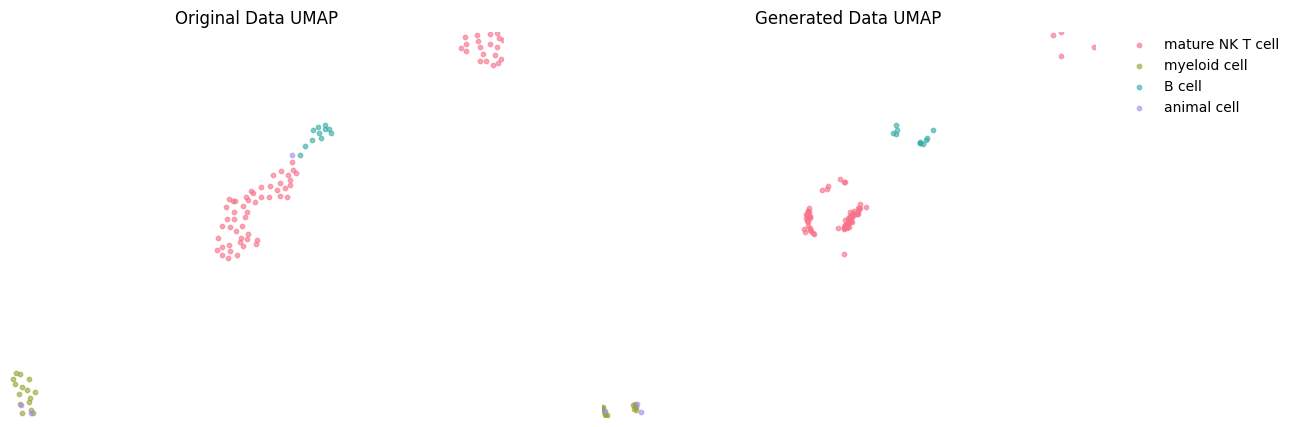

In [20]:
import umap
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.decomposition import PCA

np.random.seed(2024)

original_data = adata.X  
generated_data = adata.obsm['generate_X']

n_pcs = 40
pca_model = PCA(n_components=n_pcs, svd_solver='arpack', random_state=2024)
original_pca = pca_model.fit_transform(original_data) 
generated_pca = pca_model.transform(generated_data)    

umap_model = umap.UMAP(
    n_neighbors=10,       
    min_dist=0.5,          
    metric='euclidean',    
    random_state=2024
).fit(original_pca)

original_umap = umap_model.transform(original_pca)
generated_umap = umap_model.transform(generated_pca)

all_points = np.vstack([original_umap, generated_umap])
x_min, x_max = all_points[:, 0].min(), all_points[:, 0].max()
y_min, y_max = all_points[:, 1].min(), all_points[:, 1].max()

cell_types = adata.obs['cell_type'].unique()
palette = sns.color_palette("husl", n_colors=len(cell_types))
color_dict = {ct: palette[i] for i, ct in enumerate(cell_types)}

plt.figure(figsize=(14, 5))

plt.subplot(121)
for ct in cell_types:
    mask = adata.obs['cell_type'] == ct
    plt.scatter(
        original_umap[mask, 0], original_umap[mask, 1],
        s=10, label=ct, color=color_dict[ct], alpha=0.6
    )
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.title('Original Data UMAP')
plt.axis('off')

plt.subplot(122)
for ct in cell_types:
    mask = adata.obs['cell_type'] == ct
    plt.scatter(
        generated_umap[mask, 0], generated_umap[mask, 1],
        s=10, label=ct, color=color_dict[ct], alpha=0.6
    )
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.title('Generated Data UMAP')
plt.axis('off')

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    borderaxespad=0.,
    frameon=False
)

By batch

Text(0.5, 1.0, 'Overlay UMAP Projection\nOriginal vs Generated Cells')

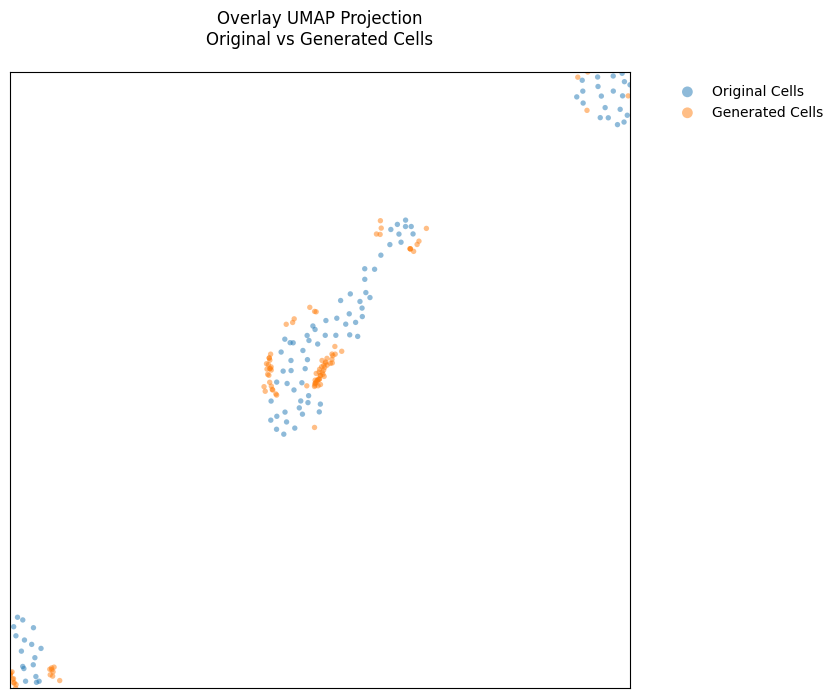

In [21]:
plt.figure(figsize=(8, 8))

plt.scatter(
    original_umap[:, 0], original_umap[:, 1],
    s=15, alpha=0.5, 
    c='#1f77b4',  
    edgecolor='none',
    label='Original Cells'
)

plt.scatter(
    generated_umap[:, 0], generated_umap[:, 1],
    s=15, alpha=0.5,
    c='#ff7f0e', 
    edgecolor='none',
    label='Generated Cells'
)

plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.xticks([])
plt.yticks([])

plt.legend(
    loc='upper left',
    bbox_to_anchor=(1.05, 1),
    frameon=False,
    markerscale=2,  
    fontsize=10
)
plt.title('Overlay UMAP Projection\nOriginal vs Generated Cells', pad=20)

#### Metrics calculation

In [ ]:
import numpy as np
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial.distance import euclidean
from sklearn.metrics import pairwise_distances

cell_data = adata.X
cell_gen = adata.obsm['generate_X']

cell_data_mean = cell_data.mean(axis=0)
cell_gen_mean = cell_gen.mean(axis=0)

spearman_corr = spearmanr(cell_data_mean, cell_gen_mean).correlation
print(f"Spearman correlation: {spearman_corr}")

pearson_corr = np.corrcoef(cell_data_mean, cell_gen_mean)[0][1]
print(f"Pearson correlation: {pearson_corr}")

euclidean_distance = euclidean(cell_data_mean, cell_gen_mean)
print(f"Euclidean distance: {euclidean_distance}")

cosine_sim = cosine_similarity([cell_data_mean], [cell_gen_mean])[0][0]
print(f"Cosine similarity: {cosine_sim}")

def gaussian_kernel(x, y, sigma=1.0):
    pairwise_sq_dists = pairwise_distances(x[:, None], y[:, None], metric='sqeuclidean')
    return np.exp(-pairwise_sq_dists / (2 * sigma**2))

def compute_mmd(x, y, kernel):
    xx = kernel(x, x)
    yy = kernel(y, y)
    xy = kernel(x, y)
    return xx.mean() + yy.mean() - 2 * xy.mean()

mmd = compute_mmd(cell_data_mean, cell_gen_mean, gaussian_kernel)
print(f"MMD: {mmd}")

Spearman correlation: 0.9868321468972858
Pearson correlation: 0.9936390118883456
Euclidean distance: 2.3575243949890137
Cosine similarity: 0.9944088459014893
